In [ ]:
### To implement SOFM for character recognition

In [3]:
#  Import libraries and load MNIST

import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


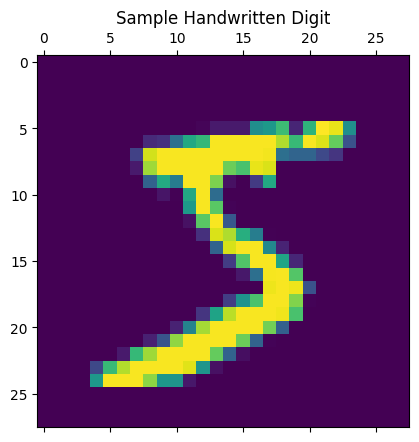

Actual digit: 5


In [4]:
# Show a handwritten digit
plt.matshow(x_train[0])
plt.title("Sample Handwritten Digit")
plt.show()

print("Actual digit:", y_train[0])

In [5]:
# Normalize and flatten the data

# Normalize
x_train = x_train / 255.0
x_test = x_test / 255.0

# Flatten
x_train_flattened = x_train.reshape(len(x_train), 784)
x_test_flattened = x_test.reshape(len(x_test), 784)

print("Training shape:", x_train_flattened.shape)
print("Testing shape:", x_test_flattened.shape)

Training shape: (60000, 784)
Testing shape: (10000, 784)


In [6]:
# Create and train the model

model = keras.Sequential([
    keras.layers.Dense(100, input_shape=(784,), activation="relu"),
    keras.layers.Dense(10, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(x_train_flattened, y_train, epochs=5)

C:\Users\VICTUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9235 - loss: 0.2695
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9634 - loss: 0.1216
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9742 - loss: 0.0855
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9805 - loss: 0.0650
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9840 - loss: 0.0516


In [7]:
# Evaluate the model

loss, accuracy = model.evaluate(x_test_flattened, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9749 - loss: 0.0781
Test Loss: 0.07806678116321564
Test Accuracy: 0.9749000072479248


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


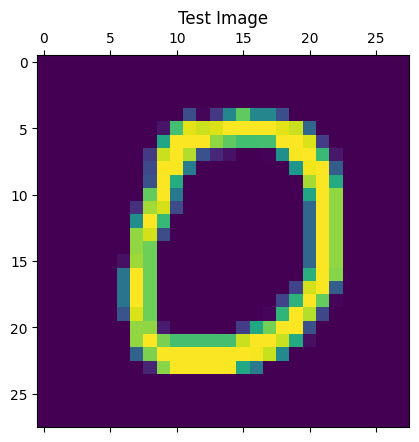

Actual digit: 0
Predicted digit: 0


In [8]:
# Predict and show a test image

# Predictions
y_pred = model.predict(x_test_flattened)

# Convert probabilities to labels
y_pred_labels = np.argmax(y_pred, axis=1)

# Show one test image
plt.matshow(x_test[10])
plt.title("Test Image")
plt.show()

print("Actual digit:", y_test[10])
print("Predicted digit:", y_pred_labels[10])

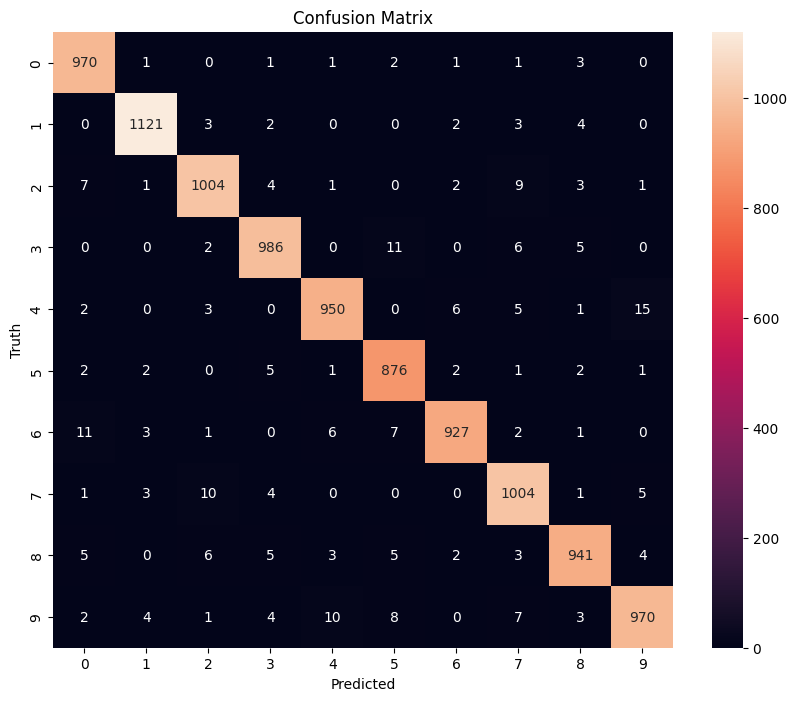

In [9]:
# Confusion matrix

# Create confusion matrix
conf_mat = tf.math.confusion_matrix(
    labels=y_test,
    predictions=y_pred_labels
)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat.numpy(), annot=True, fmt="d")

plt.xlabel("Predicted")
plt.ylabel("Truth")
plt.title("Confusion Matrix")
plt.show()